In [32]:
import jax
import jax.numpy as jnp

In [33]:
#We use JAX for numerical computations. It works similar to numpy but uses jax arrays for computation.

In [34]:
import cr.sparse as crs
import cr.sparse.dict as crdict
import cr.sparse.pursuit as pursuit

In [35]:
#cr-sparse is a JAX/XLA based library of accelerated models and algorithms for inverse problems in sparse representation and compressive sensing.

In [36]:
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

In [37]:
M = 256 #When the dimension of a signal space is stated as 256, it means that signals within this space can be represented using vectors with 256 components or dimensions.

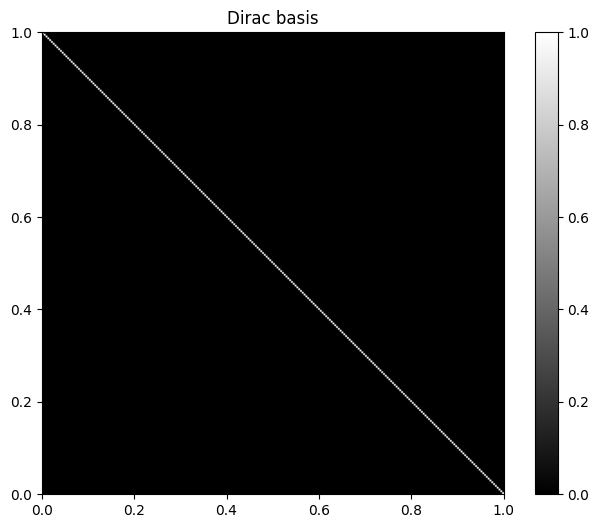

In [38]:
I = jnp.eye(M) #When you pass M to jnp.eye(M), it creates an M x M identity matrix.
fig=plt.figure(figsize=(8,6), dpi= 100, facecolor='w', edgecolor='k')
plt.imshow(I, extent=[0, 1, 0, 1])
plt.gray()
plt.colorbar()
plt.title(r'Dirac basis'); #The Dirac basis consists of vectors that are often used to represent discrete signals, where each vector has only one non-zero element.

In [39]:

#Cosine basis construction refers to the process of creating a basis set using cosine functions as the basis vectors. In signal processing and mathematics, a basis set is a collection of vectors that can be combined linearly to represent any vector in a given vector space.
Psi = crdict.cosine_basis(M) #The matrix Psi is composed of cosine waves evaluated at different points or frequencies, depending on the input parameter M. 
Psi.shape

(256, 256)

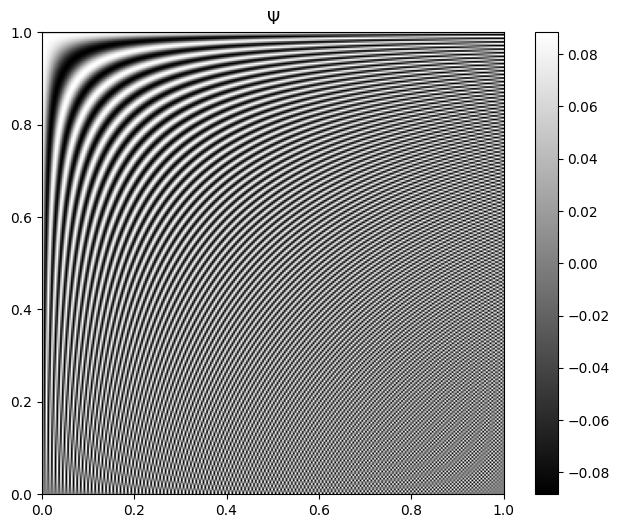

In [40]:
fig=plt.figure(figsize=(8,6), dpi= 100, facecolor='w', edgecolor='k')
plt.imshow(Psi, extent=[0, 1, 0, 1])
plt.gray()
plt.colorbar()
plt.title(r'$\Psi$');

In [41]:
#When a basis is orthonormal, each pair of different basis vectors is orthogonal (their dot product is zero), and each vector is normalized (its length or norm is one).

In [42]:
#A Dirac-Cosine dictionary is a concatenation of the two orthonormal bases (the Dirac basis and the Cosine basis). 

In [43]:
jnp.hstack([I, Psi]);

In [44]:
Phi = crdict.dirac_cosine_basis(M)

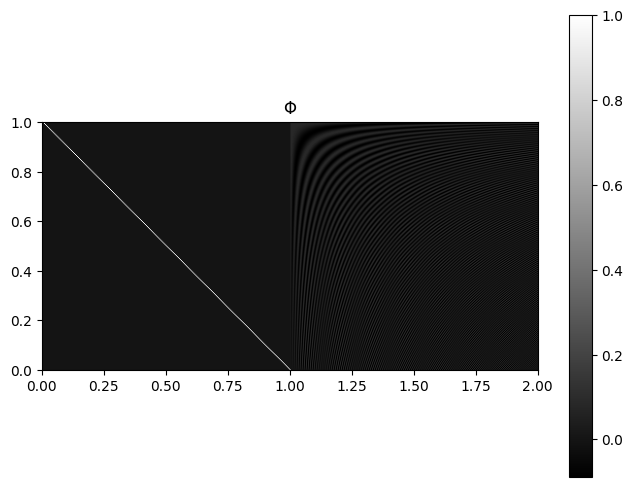

In [45]:
fig=plt.figure(figsize=(8,6), dpi= 100, facecolor='w', edgecolor='k')
plt.imshow(Phi, extent=[0, 2, 0, 1])
plt.gray()
plt.colorbar()
plt.title(r'$\Phi$');

In [46]:
#Dirac-Cosine Dictionary: Combining these two bases means creating a dictionary where each element is either a Dirac vector or a Cosine function. This hybrid dictionary is advantageous because it combines the strengths of both bases. The Dirac basis vectors are useful for representing localized, singular features in signals, while the Cosine basis functions are effective for capturing smooth, periodic components.
#In practical applications, such a dictionary might be used in scenarios like signal reconstruction, where different components of a signal might be best represented using different types of basis functions. By using a Dirac-Cosine dictionary, you can efficiently represent and reconstruct signals that have both sparse (isolated peaks) and smooth (oscillatory) components. This approach is commonly seen in compressive sensing, image processing, and audio signal analysis, where different aspects of data benefit from different mathematical representations.

In [49]:
#We can combine some of the atoms from the Dirac basis and some of the atoms from the Cosine basis, alternatively, some atoms from Dirac-Cosine dictionary to form a signal which is a mixture of impulses and sinusoids. The atoms from Dirac basis contribute the impulses and the atoms from the Dirac basis contribute the sinusoids.